# Global carbonate system: results

goSPL's carbonate module on the 250 Ma (Pangea) mesh of `continental_flux`,
1 Myr: carbonate factories on the shelves controlled by the sea-surface
temperature, pelagic carbonate above the CCD, hemipelagic clay, waves and
coastal erosion, and the coupling with the continental geochemistry. The runs
are described in `README.md` and in the header of each `input-*.yml`. The
plotting functions are in `scripts/globalcarb.py`.

In [1]:
import sys
sys.path.insert(0, 'scripts')
import matplotlib.pyplot as plt
import globalcarb as G

## The forcing

The sea-surface temperature map (warm tropics, cold poles) controls where the
shallow factory grows (18-28 degC) and lowers the pelagic carbonate rain in
cold water; the pelagic carbonate rain (before dissolution) is highest under
the equatorial belt. Replace these maps (`data/carb_maps.npz`) with
climate-model fields for a real study.

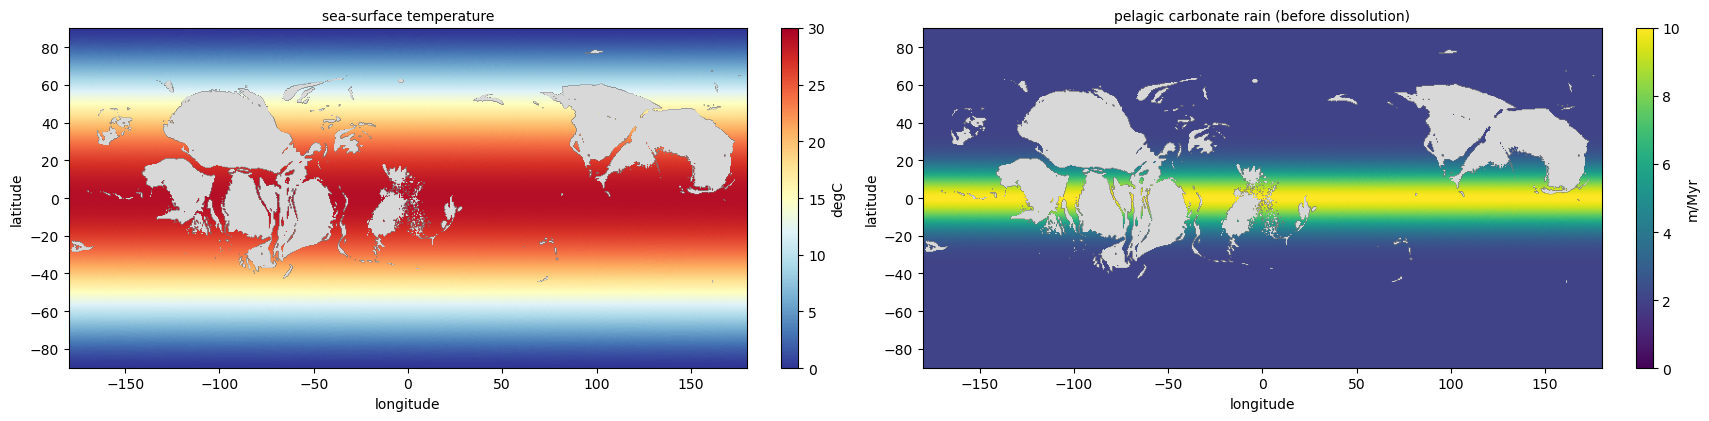

In [2]:
G.forcing();

## The reference (`input-carb.yml`)

Benthic carbonate grows on the tropical shelves and margins (Tethys, the
Pangea coasts within the warm belt), a few cells wide at this resolution.
Pelagic carbonate covers the equatorial belt where the seafloor lies above
the CCD (4500 m) and fades with depth below the lysocline (3500 m);
hemipelagic clay lines the continents. Over 1 Myr: 1.93 million km3 of
benthic carbonate (0.28 as reef framework), 1.01 million km3 of pelagic
carbonate preserved and 0.30 dissolved.

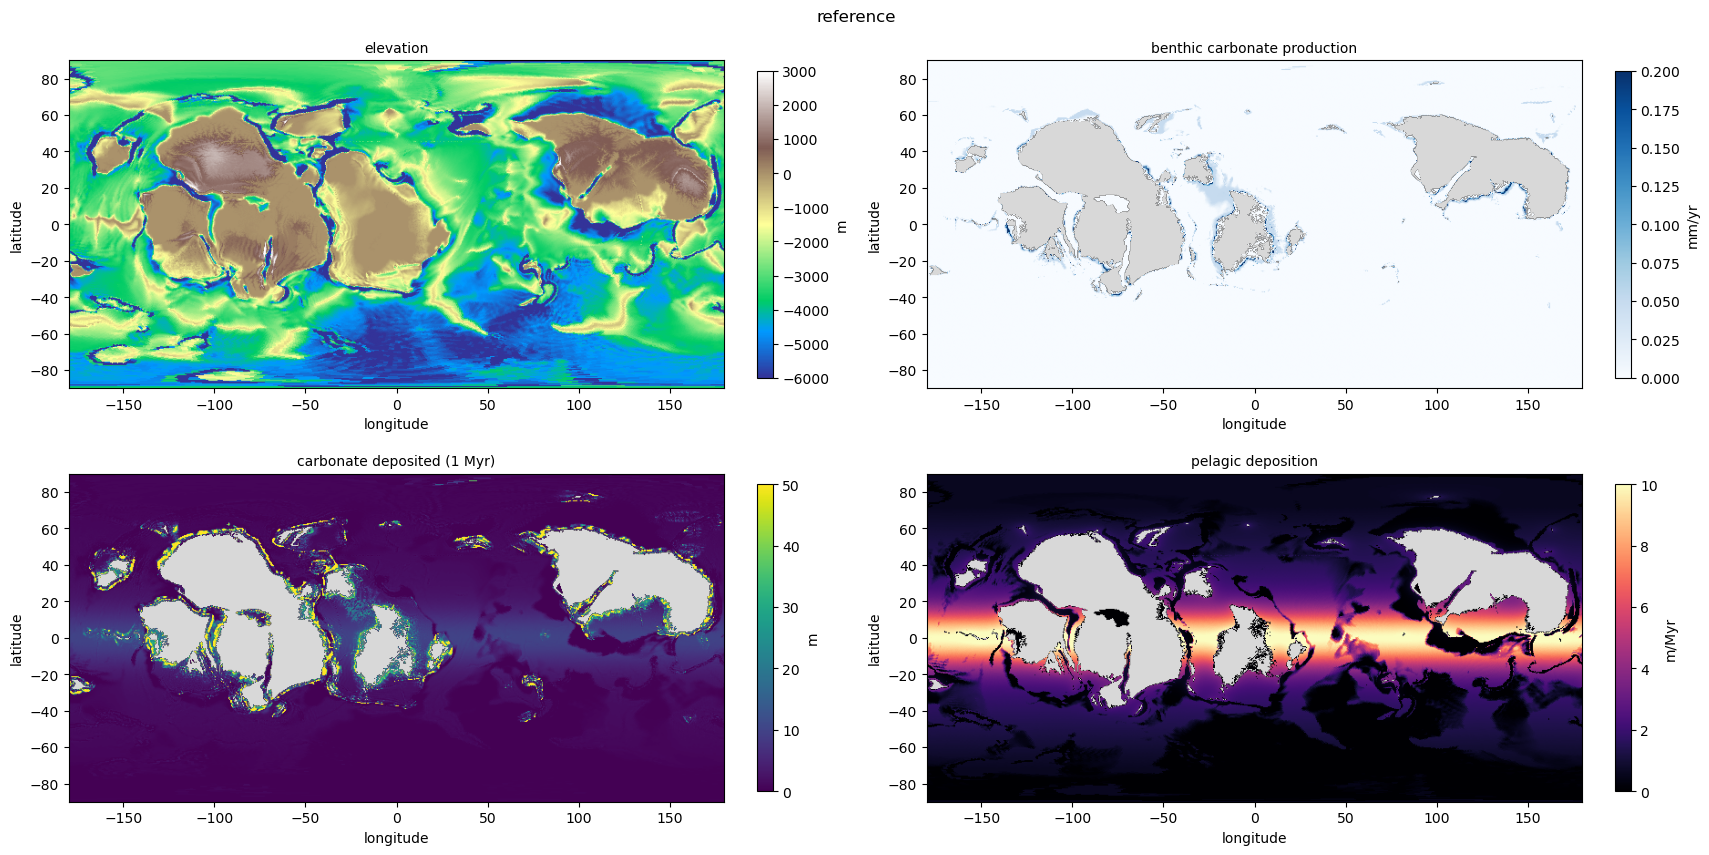

In [3]:
G.overview('sim_carb', 'reference');

## The CCD (`input-ccd_shallow.yml`)

With the lysocline at 2500 m and the CCD at 3500 m instead of 3500 and
4500 m, the pelagic carbonate kept in the basins falls by 31 % (0.69 million
km3 against 1.01) and the dissolved part doubles (0.62 against 0.30): the
equatorial belt breaks up over the deep basins. The benthic carbonate does
not change.

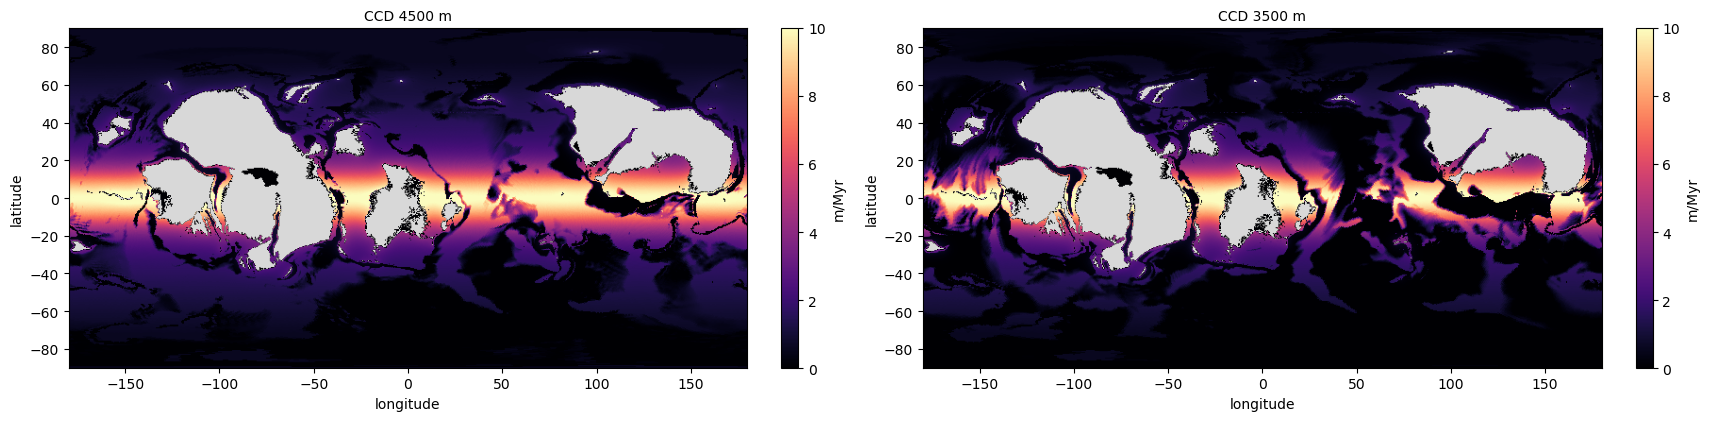

In [4]:
G.compare(['sim_carb', 'sim_ccd_shallow'], ['CCD 4500 m', 'CCD 3500 m']);

## Waves and coastal erosion (`input-waves.yml`)

The global wind belts with a 500 km fetch: open water carries the full wave
energy, the coasts in the lee of Pangea and inside the Tethys gulfs are
sheltered. The shallow factory grows less there (`wave` response), but
coastal erosion abrades the exposed shallow water and low coasts (0.22
million km3 over the run), reopening space where the factories grow again
and moving the eroded reef as carbonate sand: the benthic carbonate ends 7 %
higher than in the reference.

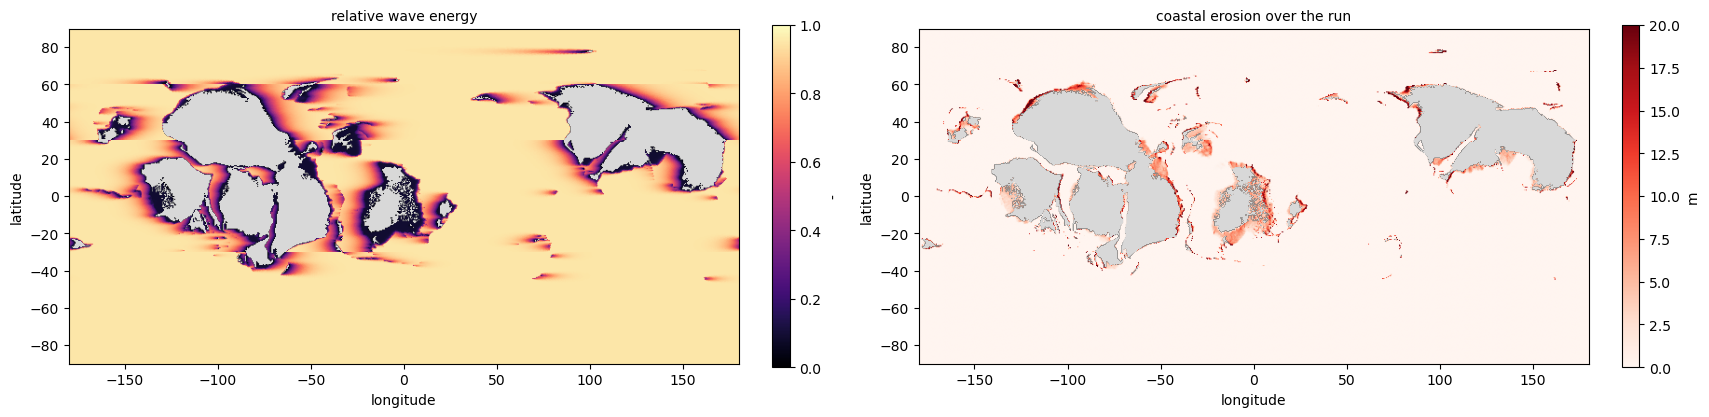

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(17, 4.4), constrained_layout=True)
lon, lat, g = G.load('sim_waves', G.steps('sim_waves')[-1], ('elev', 'waveE', 'coastEro'))
land = g['elev'] >= 0.0
G.worldmap(lon, lat, g['waveE'], ax=ax[0], title='relative wave energy', cmap='magma',
           label='-', land=land, vmin=0, vmax=1)
G.worldmap(lon, lat, g['coastEro'], ax=ax[1], title='coastal erosion over the run',
           cmap='Reds', label='m', land=land, vmin=0, vmax=20);

## Coupling with the geochemistry (`input-geochem.yml`)

The weathering of the continents (three climate provinces, groundwater and
duricrust of `continental_geochem`) delivers dissolved carbonate to the
ocean, where it accumulates in a reservoir. The carbonate the factories and
the pelagic rain bury each step cannot exceed that reservoir times the
yield (`carbonate_supply`), and what is buried is drawn from it. With
`yield: 20` the burial is limited from the first steps: scaled by 0.55 to
0.95 (0.69 on average), the reservoir drawn down from 6.6e12 to ~4.5e12
units. The benthic carbonate falls by 23 % and the pelagic by 30 %. The
`solute` response also favours the shallow factory near the large rivers.

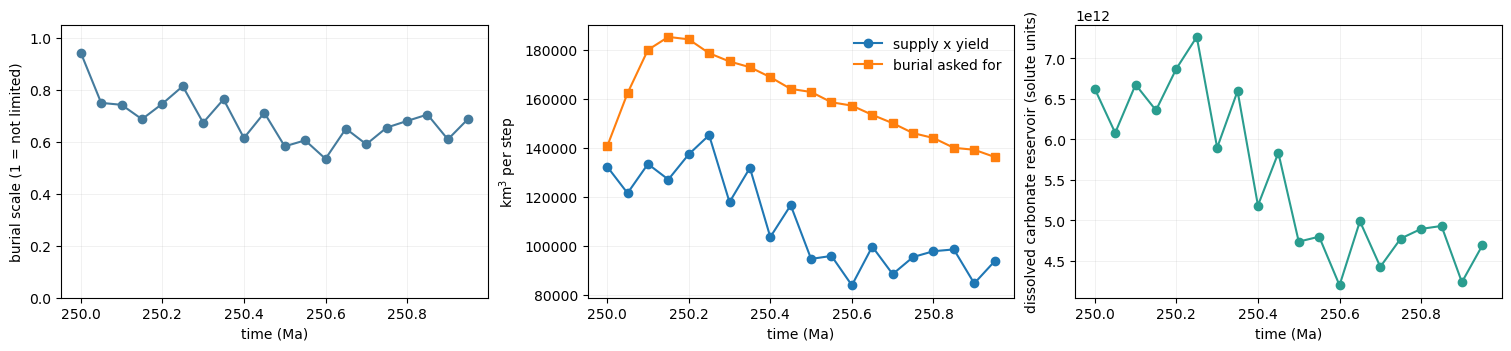

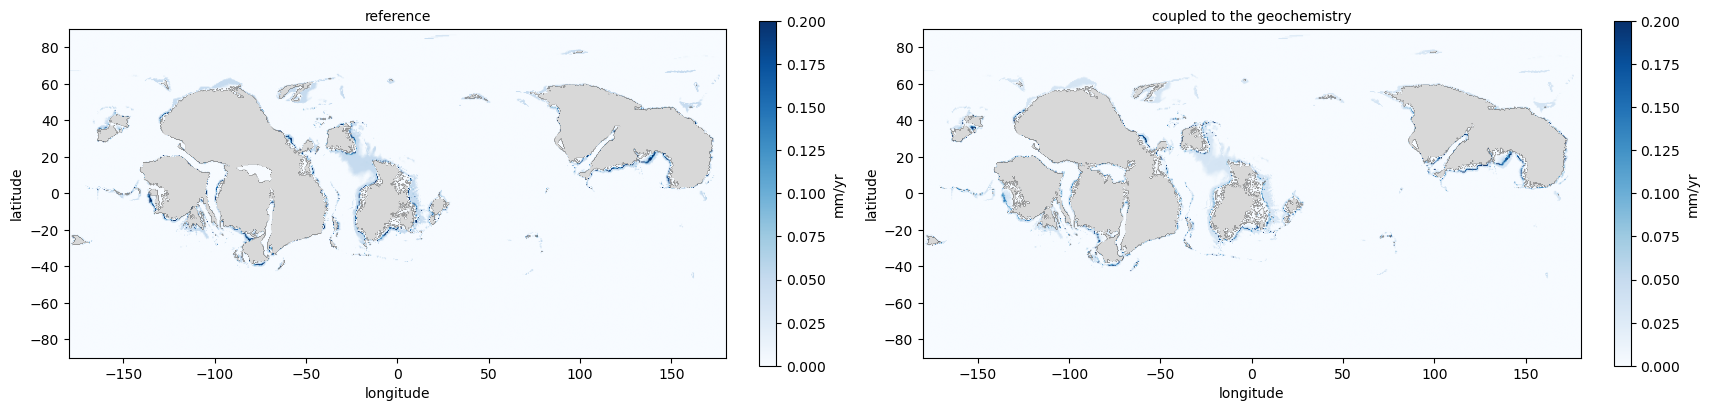

In [6]:
G.supply('geochem')
G.compare(['sim_carb', 'sim_geochem'], ['reference', 'coupled to the geochemistry'],
          key='carbProd', scale=1e3, label='mm/yr', vmax=0.2, cmap='Blues');

## Carbonate budgets

Over the run, per experiment.

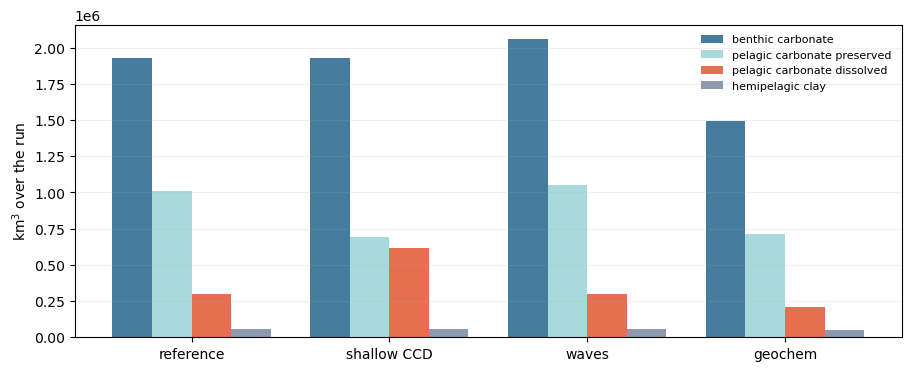

In [7]:
G.budget(['carb', 'ccd_shallow', 'waves', 'geochem'],
         ['reference', 'shallow CCD', 'waves', 'geochem']);